## Test Grid SANOS



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.grid.fitter

from quantdata.dysanos.simple.aec import load_data
data = load_data(["SPX"]).data['SPX']
print(f"/done; columns {data.keys()}")



00: Importing torch...done; this took 0.00501ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.3s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.34s.
/done; columns dict_keys(['dates', 'ask_pure_delta', 'ask_pure_dk', 'ask_pure_gamma', 'ask_pure_price', 'ask_pure_theta', 'ask_pure_vega', 'ask_vol', 'bid_pure_delta', 'bid_pure_dk', 'bid_pure_gamma', 'bid_pure_price', 'bid_pure_theta', 'bid_pure_vega', 'bid_vol', 'call_ask', 'call_bid', 'df', 'f

[0.08869111 0.25934069 0.32036203 0.38138337 0.44240471 0.50342605
 0.56444739 0.62546873 0.68649007 0.74751141 0.80853275 0.86955408
 0.93057542]
[0.99159676 0.99239402 0.99319192 0.99399046 0.99478964 0.99558946
 0.99638993 0.99719104 0.99799279 0.99879519 0.99959824 1.00040193
 1.00120626 1.00201124 1.00281687 1.00362315 1.00443008 1.00523765
 1.00604588 1.00685475 1.00766427 1.00847445]
[1.08050834 1.15254223 1.22457612 1.29661001 1.3686439  1.44067779
 1.85268587]


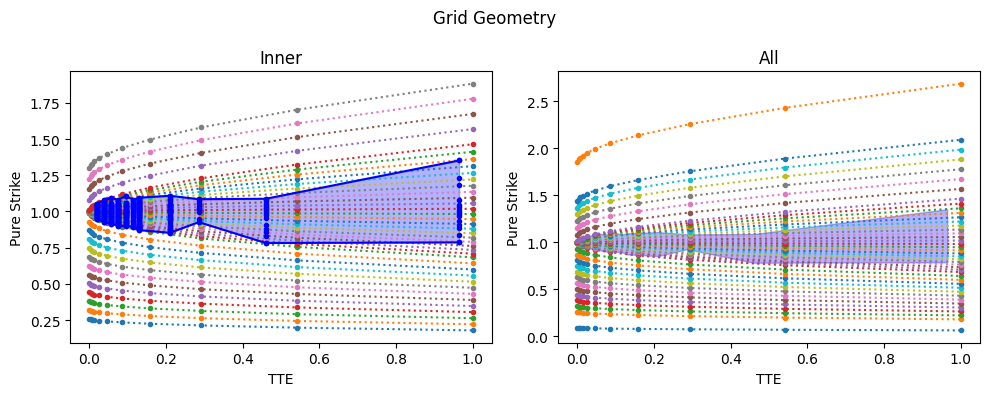

00: Solving for implied DLVs (squared) for 452 options. Mean half spread is 3.0155e-04... done with relative excess error conditional mean 4.8331e-02, std 0.0000e+00, 95th percentile 4.8331e-02, 99th percentile 4.8331e-02, 99.9th percentile 4.8331e-02 and max 4.8331e-02. This took 0.083s.
00: Computing DLV squared's... done; this tool 0.918ms.


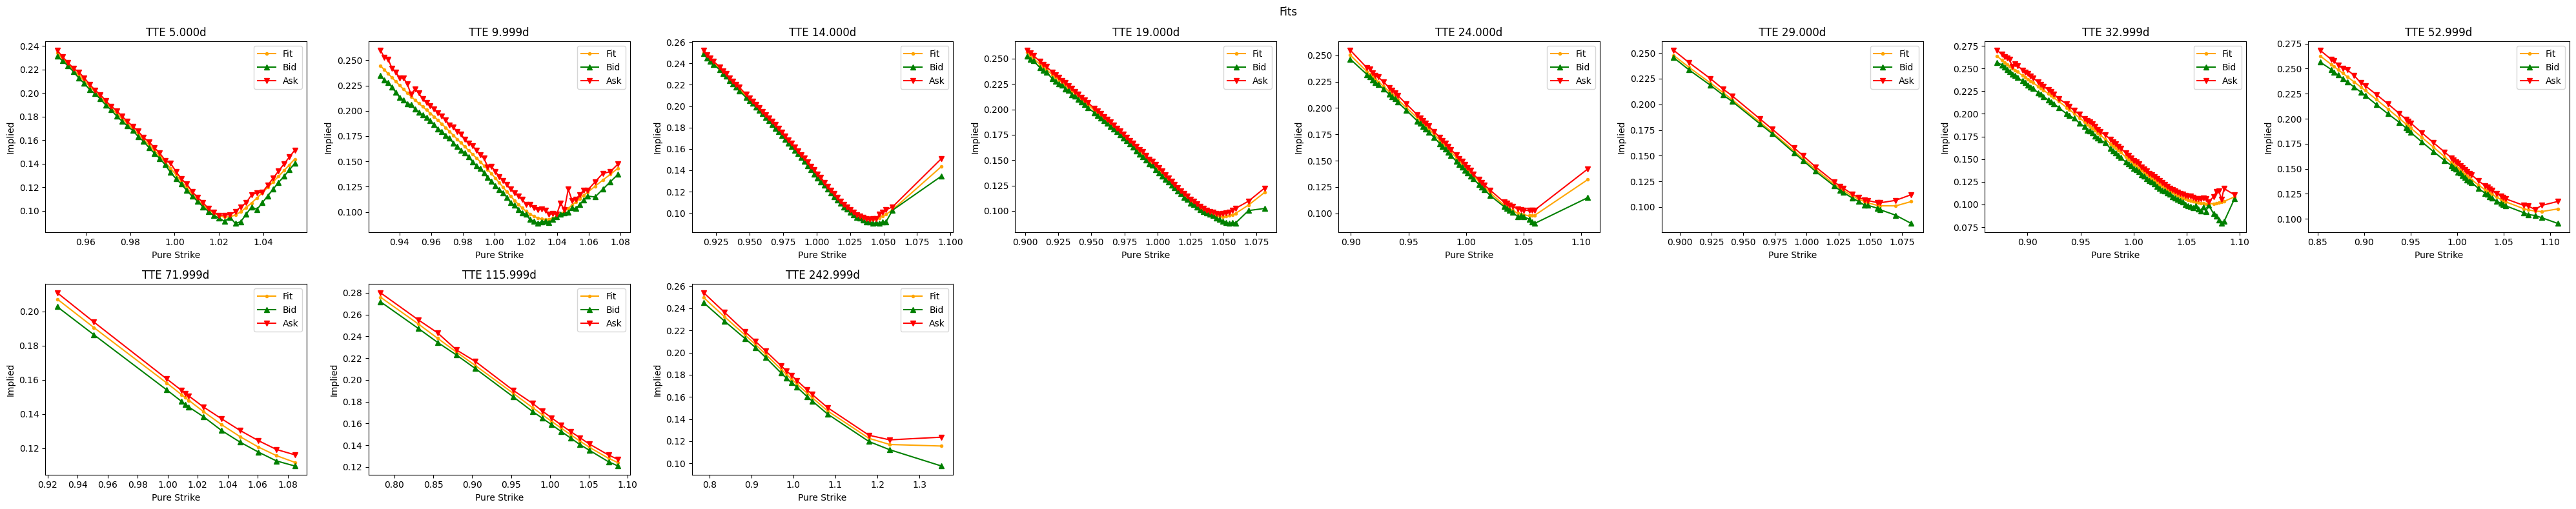

In [22]:
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.grid.fitter

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.sanos.grid import GridGeometry
from quantdata.sanos.grid.fitter import Eps, Fitter
import numpy as np

def fit(data):
    num_samples = len(data.dates)

    # construct grid
    # --------------

    grid        = GridGeometry.create_grid_nms(
                            horizon_t  = 1., 
                            num_times  = 10,
                            nms_range  = (-4,4),
                            num_nms    = 40,
                            dlv_min    = 0.01,
                            dlv_max    = 5.,
                            fwdvol_min = 0.0,
                            vol_interp = "lin_var",
                            lower_scale = 0.2,
                            upper_scale = 1.5,
                            dtype = np.float64
            )

    eps         = Eps()
    fitter      = Fitter( geometry = grid, eps = eps, debug=True, max_error = None, mid_fit_weight = 1. )

    def fit_sample( isample, store ):

        is_valid   = data.is_valid[isample,:]
        strikes    = data.pure_strike[isample,is_valid]
        tte_y      = data.tte_y[isample,is_valid]
        bid_vol    = data.bid_vol[isample,is_valid]
        ask_vol    = data.ask_vol[isample,is_valid]
        bid        = data.bid_pure_price[isample,is_valid]
        ask        = data.ask_pure_price[isample,is_valid]

        # plot the grid
        # -------------

        with figure("Grid Geometry", col_size=5, row_size=4, columns=None ) as fig_strikes:
            axD, axA    = fig_strikes.add_subplots("Inner", "All")
            axD.set_xlabel("TTE")
            axA.set_xlabel("TTE")
            axD.set_ylabel("Pure Strike")
            axA.set_ylabel("Pure Strike")
            #axA.set_yscale("log")
            #axD.set_yscale("log")

            for i in range(grid.N+2):
                axA.plot( grid.xexpiries, grid.xstrikes[:,i], ".:")
                if i>0 and i<grid.N-1:  
                    axD.plot( grid.xexpiries, grid.xstrikes[:,i], ".:" )
                    
            fig_strikes.render()
            store = fig_strikes.store()

            def plot_strikes(store):
                utty, inv = np.unique(tte_y, return_inverse=True)

                min_strike = np.full(len(utty), np.inf, dtype=strikes.dtype)
                max_strike = np.full(len(utty), -np.inf, dtype=strikes.dtype)

                np.minimum.at(min_strike, inv, strikes)
                np.maximum.at(max_strike, inv, strikes)
            
                store.clear()
                store += axA.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")
                store += axD.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")            
                store += axD.plot(utty, min_strike, ".-", color="blue")
                store += axD.plot(utty, max_strike, ".-", color="blue")
                store += axD.plot(tte_y, strikes, ".", color="blue")
                fig_strikes.render()

                return utty, min_strike, max_strike

            plot_strikes(store)

        # compute prices, dlvs
        # --------------------

        dlvsqs, fit_prices, densities = \
            fitter( fwd_vols     = 0.05,
                    opt_strikes  = strikes,
                    opt_bid      = bid,
                    opt_ask      = ask,
                    opt_tte      = tte_y,
                    opt_is_calls = None,
                    opt_mask     = None,
                    return_only_dlvsqs = False,
                    verbose      = Context.all ) 
            
        assert fit_prices.shape == strikes.shape, f"Expected fit_prices to have shape {strikes.shape}, got {fit_prices.shape}"
        fit_vols = bs.implied(strikes, fit_prices, sqrtT = np.sqrt(tte_y) )

        with figure("Fits", col_size=5, row_size=4, columns=8 ) as fig_fits:

            uttys = np.unique(tte_y)

            for utty in uttys:
                mask = tte_y == utty
                ax = fig_fits.add_subplot(f"TTE {utty*DAYS_PER_YEAR:.3f}d")
                ax.set_xlabel("Pure Strike")
                ax.set_ylabel("Implied")

                istrike = strikes[mask]

                if True:
                    ax.plot(istrike, fit_vols[mask], ".-", color="orange", label="Fit")
                    ax.plot(istrike, bid_vol[mask], "^-", color="green", label="Bid")
                    ax.plot(istrike, ask_vol[mask], "v-", color="red", label="Ask")
                else:
                    ax.plot(istrike, fit_prices[mask], ".-", color="orange", label="Fit")
                    ax.plot(istrike, bid[mask], "^-", color="green", label="Bid")
                    ax.plot(istrike, ask[mask], "v-", color="red", label="Ask")
                ax.legend()

        # Double check DLV pricing
        # ------------------------

    fit_sample(0, store)

fit(data)
